# Loading cleaned data

In [1]:
import pandas as pd
from pymatgen.core import Composition

df=pd.read_csv('./data/data_cleaned.csv')
df['composition'] = df['composition'].apply(lambda x: Composition(x))
df

,composition,Density
0,"(Li, O, Na, Si, K, Ge, Zr)",2.820
1,"(Li, O, Na, Si, K, Ge, Zr, Ta)",2.918
2,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.482
3,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.893
4,"(Li, O, Na, Si, K, Ge, Zr, Ta)",4.335
...,...,...
76588,"(O, Mg, Al, Si, Ca, Y, Sn)",2.835
76589,"(O, Mg, Al, Si, Ca, Y, Sn)",2.785
76590,"(B, O, Mg, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.617
76591,"(O, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.686


# Adding fraction of formers, inetrmediate, modifier and anion atoms

In [2]:
formers = ['B', 'Si', 'Ge', 'As', 'P', 'Sb', 'In', 'Tl', 'Sn', 'Pb', 'Se']
inters = ['Fe', 'Al', 'Te', 'Se', 'Mo', 'W', 'Bi', 'V', 'S']
anions = ['O', 'F']

def get_frac(comp, atoms):
    frac=0
    for atom in atoms:
        frac=frac+comp.get_atomic_fraction(atom)
    return frac 

df['formers_frac']=df['composition'].apply(lambda x: get_frac(x, formers))
df['inters_frac']=df['composition'].apply(lambda x: get_frac(x, inters))
df['anions_frac']=df['composition'].apply(lambda x: get_frac(x, anions))
df['modifiers_frac']=1-df['formers_frac']-df['inters_frac']-df['anions_frac']

df

,composition,Density,formers_frac,inters_frac,anions_frac,modifiers_frac
0,"(Li, O, Na, Si, K, Ge, Zr)",2.820,0.210333,0.000000,0.571667,0.218000
1,"(Li, O, Na, Si, K, Ge, Zr, Ta)",2.918,0.205592,0.000000,0.575000,0.219408
2,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.482,0.187500,0.000000,0.587500,0.225000
3,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.893,0.167059,0.000000,0.601176,0.231765
4,"(Li, O, Na, Si, K, Ge, Zr, Ta)",4.335,0.148889,0.000000,0.613333,0.237778
...,...,...,...,...,...,...
76588,"(O, Mg, Al, Si, Ca, Y, Sn)",2.835,0.199590,0.074969,0.625666,0.099775
76589,"(O, Mg, Al, Si, Ca, Y, Sn)",2.785,0.202432,0.074258,0.625485,0.097826
76590,"(B, O, Mg, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.617,0.239031,0.073682,0.637540,0.049747
76591,"(O, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.686,0.236167,0.070976,0.635921,0.056935


# MAGPIE features

In [4]:
from matminer.featurizers.composition import ElementProperty

ep_feat = ElementProperty.from_preset(preset_name="magpie", impute_nan=True)
#ep_feat.set_n_jobs(2) # Ограничение процессов

df_magpie = ep_feat.featurize_dataframe(df, col_id="composition", ignore_errors=True)  # input the "composition" column to the featurizer

df_magpie=df_magpie.dropna(how='any', axis=0) #usunięcie kolumn z NaN

df_magpie.to_csv('./data/magpie_feat_data.csv', index=False)

df_magpie

ElementProperty: 100%|██████████| 76593/76593 [1:11:36<00:00, 17.83it/s]


,composition,Density,formers_frac,inters_frac,anions_frac,modifiers_frac,MagpieData minimum Number,MagpieData maximum Number,MagpieData range Number,MagpieData mean Number,...,MagpieData range GSmagmom,MagpieData mean GSmagmom,MagpieData avg_dev GSmagmom,MagpieData mode GSmagmom,MagpieData minimum SpaceGroupNumber,MagpieData maximum SpaceGroupNumber,MagpieData range SpaceGroupNumber,MagpieData mean SpaceGroupNumber,MagpieData avg_dev SpaceGroupNumber,MagpieData mode SpaceGroupNumber
0,"(Li, O, Na, Si, K, Ge, Zr)",2.820,0.210333,0.000000,0.571667,0.218000,3.0,40.0,37.0,10.232666,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,103.477663,104.589464,12.0
1,"(Li, O, Na, Si, K, Ge, Zr, Ta)",2.918,0.205592,0.000000,0.575000,0.219408,3.0,73.0,70.0,10.607236,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,102.789792,104.408270,12.0
2,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.482,0.187500,0.000000,0.587500,0.225000,3.0,73.0,70.0,12.025000,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,100.200000,103.635000,12.0
3,"(Li, O, Na, Si, K, Ge, Zr, Ta)",3.893,0.167059,0.000000,0.601176,0.231765,3.0,73.0,70.0,13.601764,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,97.372349,102.647698,12.0
4,"(Li, O, Na, Si, K, Ge, Zr, Ta)",4.335,0.148889,0.000000,0.613333,0.237778,3.0,73.0,70.0,15.002778,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,94.859446,101.640919,12.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76588,"(O, Mg, Al, Si, Ca, Y, Sn)",2.835,0.199590,0.074969,0.625666,0.099775,8.0,50.0,42.0,10.949793,...,0.0,0.0,0.0,0.0,12.0,227.0,215.0,89.779744,97.328300,12.0
76589,"(O, Mg, Al, Si, Ca, Y, Sn)",2.785,0.202432,0.074258,0.625485,0.097826,8.0,50.0,42.0,10.810901,...,0.0,0.0,0.0,0.0,12.0,227.0,215.0,89.921118,97.476960,12.0
76590,"(B, O, Mg, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.617,0.239031,0.073682,0.637540,0.049747,5.0,56.0,51.0,10.870135,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,89.282309,98.541146,12.0
76591,"(O, Al, Si, Ca, Sr, Zr, Sn, Ba)",2.686,0.236167,0.070976,0.635921,0.056935,8.0,56.0,48.0,11.158208,...,0.0,0.0,0.0,0.0,12.0,229.0,217.0,90.057390,99.276704,12.0


# MEREDIG features

In [ ]:
from matminer.featurizers.composition import Meredig

ep_feat = Meredig(impute_nan=True)
df_meredig = ep_feat.featurize_dataframe(df, col_id="composition", ignore_errors=True)  # input the "composition" column to the featurizer

df_meredig=df_meredig.dropna(how='any', axis=0) #usunięcie kolumn z NaN

df_meredig.to_csv('./data/meredig_feat_data.csv', index=False)

df_meredig

# Custom features

In [ ]:
import pandas as pd

df1 = pd.read_csv('./data/meredig_feat_data.csv')
df2 = pd.read_csv('./data/magpie_feat_data.csv').drop(columns=['composition', 'Density'])

df_custom = pd.concat([df1, df2], axis=1)

columns_to_remove = ['mean ', 'range ',  'avg ', 'frac ', '_frac', 'Magpie']
columns_to_drop_manual= [col for col in df_custom.columns if any(term in col for term in columns_to_remove)]

print("Features to remove: ", columns_to_drop_manual)

df_custom = df_custom.drop(columns=columns_to_drop_manual)

print("No features: ", df_custom.shape[1])

df_custom.to_csv('./data/custom_feat_data.csv', index=False)

df_custom

# Feature engeneering

In [1]:
custom=False # custom=False - for Meredig or Magpie features
magpie=True # magpie=False - for Meredig features / magpie=True - for Magpie features

## Lading data

y1 - Density 

y2 - Molar volume

In [2]:
from pymatgen.core import Composition
import pandas as pd

if custom:
    feat_df = pd.read_csv('./data/custom_feat_data.csv') #Custom features
elif magpie:
    feat_df = pd.read_csv('./data/magpie_feat_data.csv') #Magpie features
else:
    feat_df = pd.read_csv('./data/meredig_feat_data.csv') #Meredig features

y1 = feat_df['Density']
X = feat_df.drop(columns=['composition', 'Density'])

feat_df['comp'] = feat_df['composition'].apply(lambda x: Composition(x))
feat_df['molar_weight'] = feat_df['comp'].apply(lambda x: x.weight)
feat_df['molar_volume'] = feat_df['molar_weight'] / feat_df['Density']

y2 = feat_df['molar_volume']

## Removing mostly null features (0 values > 90%)

In [3]:
threshold = 0.9
columns_to_drop_null = [col for col in X.columns if (X[col] == 0).mean() > threshold] 
print("Features to remove: ", columns_to_drop_null)

X = X.drop(columns=columns_to_drop_null)

print("No features: ", X.shape[1])

Features to remove:  ['MagpieData minimum NpValence', 'MagpieData minimum NdValence', 'MagpieData mode NdValence', 'MagpieData minimum NfValence', 'MagpieData mode NfValence', 'MagpieData minimum NsUnfilled', 'MagpieData mode NsUnfilled', 'MagpieData minimum NpUnfilled', 'MagpieData minimum NdUnfilled', 'MagpieData mode NdUnfilled', 'MagpieData minimum NfUnfilled', 'MagpieData mode NfUnfilled', 'MagpieData minimum GSbandgap', 'MagpieData mode GSbandgap', 'MagpieData minimum GSmagmom', 'MagpieData mode GSmagmom']
No features:  120


## Removing selected features

Features to remove:  ['MagpieData minimum Number', 'MagpieData maximum Number', 'MagpieData range Number', 'MagpieData mean Number', 'MagpieData avg_dev Number', 'MagpieData mode Number', 'MagpieData minimum MeltingT', 'MagpieData maximum MeltingT', 'MagpieData range MeltingT', 'MagpieData mean MeltingT', 'MagpieData avg_dev MeltingT', 'MagpieData mode MeltingT', 'MagpieData minimum Column', 'MagpieData maximum Column', 'MagpieData range Column', 'MagpieData mean Column', 'MagpieData avg_dev Column', 'MagpieData mode Column', 'MagpieData minimum Row', 'MagpieData maximum Row', 'MagpieData range Row', 'MagpieData mean Row', 'MagpieData avg_dev Row', 'MagpieData mode Row', 'MagpieData maximum NsUnfilled', 'MagpieData range NsUnfilled', 'MagpieData mean NsUnfilled', 'MagpieData avg_dev NsUnfilled', 'MagpieData maximum NpUnfilled', 'MagpieData range NpUnfilled', 'MagpieData mean NpUnfilled', 'MagpieData avg_dev NpUnfilled', 'MagpieData mode NpUnfilled', 'MagpieData maximum NdUnfilled', 'Ma

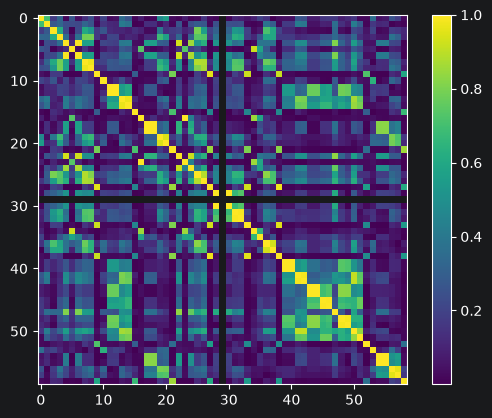

In [4]:
import matplotlib.pyplot as plt

if custom:
    columns_to_remove = []
elif magpie:
    columns_to_remove = ['Unfilled', 'GSbandgap', 'GSmagmom', 'SpaceGroupNumber', 'compound possible', ' Number', ' Row', ' Column', ' MeltingT', 'ionic char', 'norm', 'frac ']
else:
    columns_to_remove = [' fraction']

columns_to_drop_manual= [col for col in X.columns if any(term in col for term in columns_to_remove)]

print("Features to remove: ", columns_to_drop_manual)

# Usunięcie tych cech 
X = X.drop(columns=columns_to_drop_manual)

print("No features: ", X.shape[1])

corr_matrix = X.corr().abs()   # we take the absolute value
fig, ax = plt.subplots()
h = ax.imshow(corr_matrix)
plt.colorbar(h)
plt.show()

# Removing highly correlated features

Removed features: {'MagpieData mode Electronegativity', 'MagpieData avg_dev GSvolume_pa', 'MagpieData range NfValence', 'MagpieData maximum Electronegativity', 'MagpieData range MendeleevNumber', 'MagpieData mode NpValence', 'MagpieData avg_dev NfValence', 'MagpieData avg_dev NsValence', 'MagpieData avg_dev AtomicWeight', 'MagpieData avg_dev NdValence', 'MagpieData range NsValence', 'MagpieData range CovalentRadius', 'MagpieData range AtomicWeight', 'MagpieData range NdValence', 'MagpieData avg_dev MendeleevNumber', 'MagpieData range GSvolume_pa', 'MagpieData range NValence'}
No features:  42


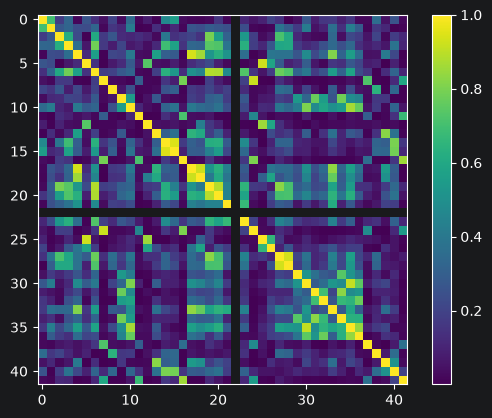

In [5]:
# Obliczanie macierzy korelacji 
corr_matrix = X.corr().abs()

# Wypisanie par cech z korelacją powyżej 0.95 
high_corr_pairs = [(i, j) for i in corr_matrix.columns for j in corr_matrix.columns if i != j and corr_matrix.loc[i, j] > 0.95] 

# Usunięcie jednej cechy z każdej pary 
columns_to_drop_corr = set() 
for i, j in high_corr_pairs: 
    if i not in columns_to_drop_corr and j not in columns_to_drop_corr: 
        columns_to_drop_corr.add(j) 

X = X.drop(columns=columns_to_drop_corr) 

print("Removed features:", columns_to_drop_corr) 
print("No features: ", X.shape[1])

corr_matrix = X.corr().abs()
fig, ax = plt.subplots()
h = ax.imshow(corr_matrix)
plt.colorbar(h)
plt.show()

# Saving files

In [6]:
drop_col=columns_to_drop_null + list(columns_to_drop_corr) + list(columns_to_drop_manual)

if custom:
    file_name = './data/corr-pairs_custom.txt'
elif magpie:
    file_name = './data/corr-pairs_magpie.txt'
else:
    file_name = './data/corr-pairs_meredig.txt'
with open(file_name, 'w') as plik: 
    for element in high_corr_pairs: plik.write(f"{element}\n")

if custom:
    file_name = './data/col_to_drop_custom.txt'
elif magpie:
    file_name = './data/col_to_drop_magpie.txt'
else:
    file_name = './data/col_to_drop_meredig.txt'
with open(file_name, 'w') as plik: 
    for element in drop_col: plik.write(f"{element}\n")

if custom:  
    file_name = './data/features_custom.txt'
elif magpie:
    file_name = './data/features_magpie.txt'
else:
    file_name = './data/features_meredig.txt'
with open(file_name, 'w') as plik: 
    for element in list(X.columns): plik.write(f"{element}\n")

if custom:
    file_name = './data/X_custom.csv'
elif magpie:
    file_name = './data/X_magpie.csv'
else:
    file_name = './data/X_meredig.csv'
X.to_csv(file_name, index=False)

if custom:
    file_name = './data/y1_custom.csv'
elif magpie:
    file_name = './data/y1_magpie.csv'
else:
    file_name = './data/y1_meredig.csv'
y1.to_csv(file_name, index=False)

if custom: 
    file_name = './data/y2_custom.csv'
elif magpie:
    file_name = './data/y2_magpie.csv'
else:
    file_name = './data/y2_meredig.csv'
y2.to_csv(file_name, index=False)